In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [3]:
df = pd.read_csv('/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', encoding='latin-1')

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:

df = df[['v1', 'v2']].copy()

df.columns = ['label', 'message']

df = df.dropna()

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df['label'].value_counts())


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:

df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print(df['label'].value_counts())
print(df.head())


label
0    4825
1     747
Name: count, dtype: int64
   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...


In [6]:

X = df['message']
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))


Training data: 4457
Testing data: 1115


In [7]:

vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (4457, 5000)
X_test shape: (1115, 5000)


In [8]:

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


In [9]:

# Number of samples and features
n_samples, n_features = X_train.shape

# Initialize weights and bias
w = np.zeros(n_features)
b = 0

# Hyperparameters
learning_rate = 0.5
epochs = 1000
beta = 0.9

# Initialize momentum
vw = np.zeros(n_features)
vb = 0

# Store loss values
loss_history = []

# Gradient Descent with Momentum
for epoch in range(epochs):

    # Forward propagation
    z = X_train @ w + b
    y_pred = sigmoid(z)

    # Calculate error
    error = y_pred - y_train

    # Calculate gradients
    dw = np.asarray(X_train.T @ error).ravel() / n_samples
    db = np.mean(error)

    # Momentum update
    vw = beta * vw + (1 - beta) * dw
    vb = beta * vb + (1 - beta) * db

    # Update weights and bias
    w = w - learning_rate * vw
    b = b - learning_rate * vb

    # Calculate loss
    z = X_train @ w + b
    y_pred = sigmoid(z)

    epsilon = 1e-15

    loss = -np.mean(
        y_train * np.log(y_pred + epsilon) +
        (1 - y_train) * np.log(1 - y_pred + epsilon)
    )

    loss_history.append(loss)

print("Final Training Loss:", loss_history[-1])


Final Training Loss: 0.23683388211451317


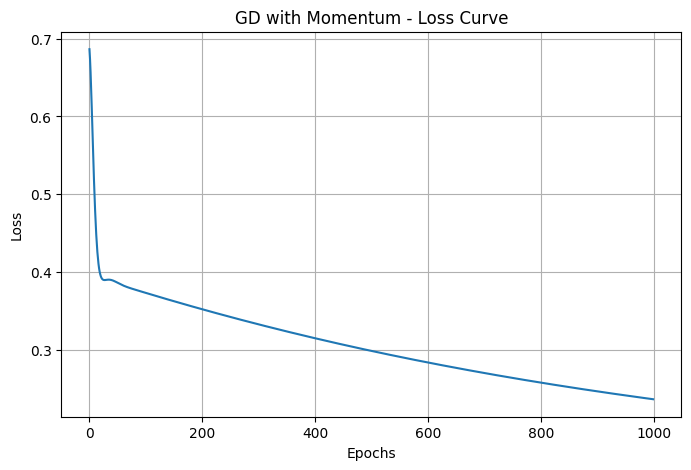

In [10]:

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("GD with Momentum - Loss Curve")

plt.grid()
plt.show()


In [11]:

# Predict on test data
y_prob = sigmoid(X_test @ w + b)

y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

# Calculate test loss
epsilon = 1e-15

test_loss = -np.mean(
    y_test * np.log(y_prob + epsilon) +
    (1 - y_test) * np.log(1 - y_prob + epsilon)
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("Loss:", test_loss)


Accuracy: 0.8860986547085202
Precision: 1.0
Recall: 0.1476510067114094
F1-Score: 0.2573099415204678
Loss: 0.23577859347694566
